# Simple Linear Regression

Fit and interpret a one-predictor regression of salary on training hours.

The estimated regression equation is:

Salary = 63.971 + 0.2951 × Training Hours

The intercept is 63.971, representing the predicted salary (in thousands of euros) when training hours equal zero.

The slope is 0.2951, meaning that each additional hour of training is associated with an average increase of approximately €295.10 in salary.

The R-squared is 0.092, indicating that training hours explain 9.2% of the variation in salary. The relationship is statistically significant (p-value less than 0.001).

Overall, the model indicates a positive association between training hours and salary, although other factors also contribute to differences in salary.

In [4]:
import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import statsmodels.formula.api as smf

sns.set_theme(style="whitegrid")

from pathlib import Path


def find_repo_root(start=Path.cwd()):
    for path in [start, *start.parents]:
        if (path / "pyproject.toml").exists():
            return path
    raise RuntimeError("Could not find repository root")


ROOT = find_repo_root()
DATA = ROOT / "data"

In [11]:
df = pd.read_csv(DATA / "career_outcomes.csv")
df.head()

,experience_years,education_years,training_hours,sector,remote,ai_tool_use,salary_k_eur,promoted
0,1.2,12,38.2,technology,0,4.8,60.2,0
1,5.1,16,20.7,technology,1,4.0,66.5,1
2,8.5,14,60.5,retail,0,8.2,76.5,1
3,9.7,16,38.7,finance,0,0.7,84.7,0
4,2.5,16,60.7,public,0,4.7,67.6,0


## Analytic question

How much does salary tend to change with additional training hours? State the outcome, predictor, expected direction, and one plausible omitted variable.

--The outcome variable is salary_k_eur, which represents salary in thousands of euros, and the predictor variable is training_hours, which represents the number of training hours.

I expect a positive relationship between these variables, meaning that employees with more training hours tend to have higher salaries.

One plausible omitted variable is work experience, because employees with more experience may receive higher salaries and may also have more opportunities for training.

[Text(0.5, 1.0, 'Salary and training hours'),
 Text(0.5, 0, 'Training hours'),
 Text(0, 0.5, 'Salary, thousand EUR')]

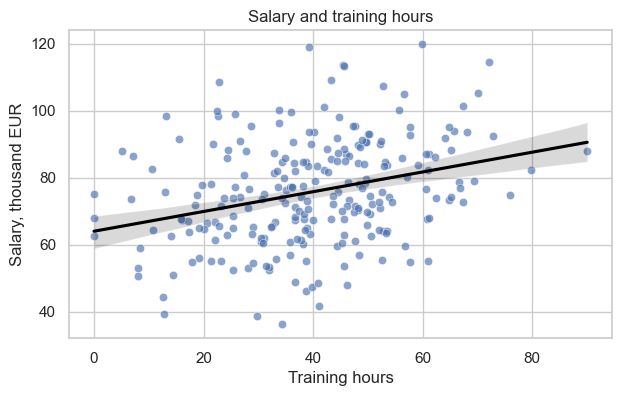

In [12]:
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=df, x="training_hours", y="salary_k_eur", alpha=0.65, ax=ax)
sns.regplot(data=df, x="training_hours", y="salary_k_eur", scatter=False, color="black", ax=ax)
ax.set(title="Salary and training hours", xlabel="Training hours", ylabel="Salary, thousand EUR")

In [13]:
model = smf.ols("salary_k_eur ~ training_hours", data=df).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:           salary_k_eur   R-squared:                       0.092
Model:                            OLS   Adj. R-squared:                  0.088
Method:                 Least Squares   F-statistic:                     24.02
Date:                Tue, 03 Nov 2026   Prob (F-statistic):           1.76e-06
Time:                        21:16:05   Log-Likelihood:                -989.05
No. Observations:                 240   AIC:                             1982.
Df Residuals:                     238   BIC:                             1989.
Df Model:                           1                                         
Covariance Type:            nonrobust                                         
                     coef    std err          t      P>|t|      [0.025      0.975]
----------------------------------------------------------------------------------
Intercept         63.9710      2.577     24.

In [14]:
intercept = model.params["Intercept"]
slope = model.params["training_hours"]
training_sd = df["training_hours"].std()
effect_per_hour = slope * training_sd
print(f"Predicted salary with no training: {intercept:.1f} thousand EUR")
print(f"Estimated salary change per additional training hour: {effect_per_hour:.2f} thousand EUR")

Predicted salary with no training: 64.0 thousand EUR
Estimated salary change per additional training hour: 4.75 thousand EUR


In [15]:
new_workers = pd.DataFrame({"training_hours": [10, 40, 80]})
predictions = model.get_prediction(new_workers).summary_frame(alpha=0.05)
new_workers.join(predictions[["mean", "mean_ci_lower", "mean_ci_upper"]])

,training_hours,mean,mean_ci_lower,mean_ci_upper
0,10,66.922063,62.920192,70.923934
1,40,75.775371,73.870950,77.679793
2,80,87.579782,82.431712,92.727853


[Text(0.5, 1.0, 'Residuals versus fitted values'),
 Text(0.5, 0, 'Fitted salary'),
 Text(0, 0.5, 'Residual')]

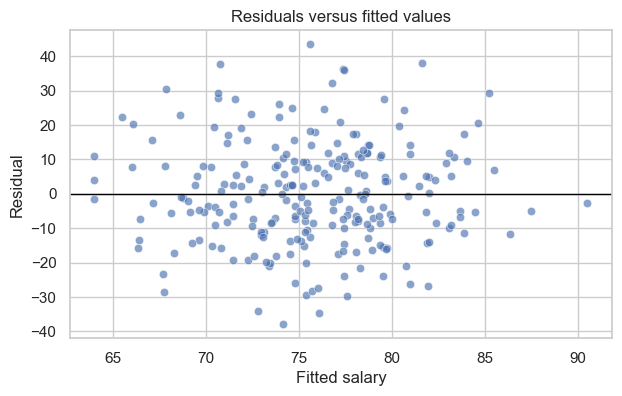

In [16]:
diagnostics = df.assign(fitted=model.fittedvalues, residual=model.resid)
fig, ax = plt.subplots(figsize=(7, 4))
sns.scatterplot(data=diagnostics, x="fitted", y="residual", alpha=0.65, ax=ax)
ax.axhline(0, color="black", linewidth=1)
ax.set(title="Residuals versus fitted values", xlabel="Fitted salary", ylabel="Residual")

## Interpretation

State the slope as an association, with units, and name one omitted variable that could confound it.

The estimated slope is 0.2951. This means that one additional hour of training is associated with an average increase of approximately 0.2951 thousand euros (or €295.10) in salary.

This is a positive association, but it does not necessarily mean that additional training directly causes higher salaries.

Work experience is one possible omitted variable that could confound this relationship, because it may influence both training hours and salary.